# Entropy and information in neural spike trains. 

This is based on the works: 

-R. R. de Ruyter van Steveninck, G. D. Lewen, S. P. Strong, R. Koberle, W. Bialek Reproducibility and Variability in Neural Spike Trains, Science 275, 1805-1808 (1997)

-K. Koch, J. McLean, M. Berry, P. Sterling, V. Balasubramanian, M. A. Efficiency of Information Transmission by Retinal Ganglion Cells Current Biology, 14, 15231530, (2004).

In [19]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
import numpy.matlib
import pandas as pd
#matplotlib inline
#plt.rcParams["font.family"] = "serif"
#plt.rcParams["mathtext.fontset"] = "dejavuserif"
#plt.rcParams["figure.figsize"] = (10, 8)
#plt.rcParams["font.size"] = 26

In [12]:
#import data
data = np.loadtxt('dati2-berry.dat')

#parameters
#time bin =10 ms
dt = 0.01
#length (in seconds) of a word
ls = 0.1
#length (in bits) of a word
l = int(ls/dt)
#length (in seconds) of a repetition
T = 26.5
#number of bins for each repetition of duration 26.5 s
M = int(T/dt)
#number of repetition of the input
Nr = 120
#number of repetitions used in the data analysis
#verify for Nrp=1, the noise entropy should be zero
Nrp = 120
#Number of words
Nwt = np.power(2,l)


#Find lines in the data delimiting neurons spike trains + add last line
Ndata = np.size(data)
Ncells = 40
tc = (np.zeros(Ncells+1)).astype(int)
tc[0:Ncells] = np.where(data == 4000)[0][:]
tc[Ncells] = Ndata

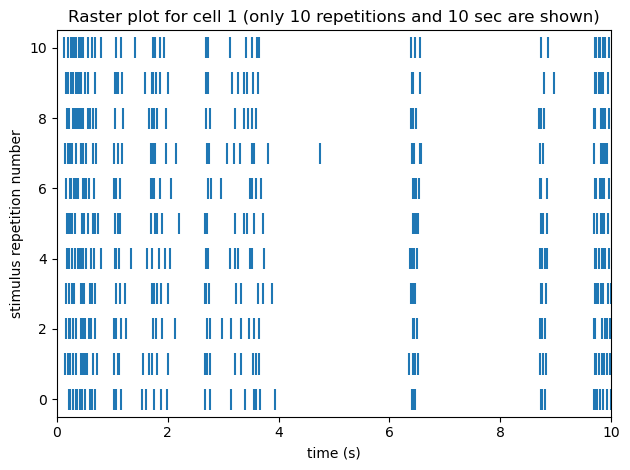

In [13]:
# Raster Plot
data0 = data[tc[0]+2:tc[1]]
x = data0%T
y = data0//T
plt.xlim([0,10])
plt.ylim([-0.5,10.5])
plt.vlines(x,y-0.3,y+0.3)
plt.xlabel('time (s)')
plt.ylabel('stimulus repetition number')
plt.title('Raster plot for cell 1 (only 10 repetitions and 10 sec are shown)')
plt.tight_layout()
plt.show()


In [14]:
#Function that converts the spikes for a single neuron into a matrix
#The matrix contains the number of spikes in a bin of size dt for each repetition (line)
def data_to_table (i):
    datai=data[tc[i]+2:tc[i+1]]
    # build the spiking matrix for the neuron i, using sparse matrix
    tt=datai%T
    #time bin of the spike (0:M-1)
    y=np.floor(tt/dt)
    #interval number (0:119)
    x=np.floor(datai//T)
    # conversion to a sparse matrix 
    z=np.ones(np.size(datai))
    s=coo_matrix((z,(x,y)),dtype=np.int8,shape=(Nr,M))
    sreal=s.toarray()
    return sreal

#Function that performs the conversion from a string of bits to an integer
#note that some elements of word can be >1; the first line makes the conversion to 0,1
def toint (word):
    y=(word[:]>0).astype(int)
    bw=[str(t) for t in y]
    bw2=''.join(bw)
    return int(bw2,2)  



## Data Structure

The raw data is a **single column of numbers containing spike times for all 40 neurons**. Markers separate the data for different neurons.

For example (illustrative values):

    4000
    4
    0.023
    0.087
    ...
    3179.842
    4000
    7
    0.041
    0.156
    ...

- `4000` marks the start of a new neuron's data.
- The next number is its **neuron label**, such as `4` or `7`. Labels are identifiers between 4 and 63 and need not be consecutive.
- The following numbers are that neuron's **spike times in seconds**, until the next `4000`.

### Movie Repetitions

The same **26.5-second movie** was presented **120 times**, giving a total recording duration of:

$$
120 \times 26.5 = 3180 \text{ seconds}.
$$

Spike times use a continuous clock across all repetitions. For example, a spike at **28.0 seconds** occurs during the **second repetition**, **1.5 seconds into the movie**:

$$
28.0 = 26.5 + 1.5.
$$

For a spike time $t$, its zero-based repetition index and time within the movie are:

$$
r = \left\lfloor \frac{t}{26.5} \right\rfloor,
\qquad
\tau = t \bmod 26.5.
$$

In Python:

    repetition = int(t // 26.5)  # 0-based: 0, ..., 119
    movie_time = t % 26.5       # time within that repetition

### Binary Representation

For analysis, each movie repetition is divided into **10 ms time bins**. Each bin is encoded as:

- **0:** no spike occurred.
- **1:** at least one spike occurred.

Each repetition contains:

$$
\frac{26.5}{0.010} = 2650 \text{ bins}.
$$

Each neuron is therefore represented by a **120 × 2650 binary matrix**:

| Repetition | Bin 0 | Bin 1 | Bin 2 | … |
|---|---:|---:|---:|---:|
| 1 | 0 | 1 | 0 | … |
| 2 | 0 | 1 | 1 | … |
| 3 | 0 | 1 | 0 | … |

**Reading across a row** shows the neuron's response during one movie presentation.

**Reading down a column** shows the variability of its response at the same movie moment across repetitions.

For entropy calculations, we group consecutive bins into binary **words**. A word of 10 bins describes 100 ms of activity. Comparing these words across repetitions at the same movie position allows us to estimate **noise entropy**.

## Question 1: Entropy of a Poisson Process

### 1a. Entropy and Entropy Rate

Assume that a neuron fires according to a homogeneous Poisson process with frequency $f$ (in Hz). The number of spikes $N$ in a time bin of duration $\Delta t$ follows a $\mathrm{Poi}(f\Delta t)$, and so:

$$
P(N=k) = \frac{(f\Delta t)^k}{k!}e^{-f\Delta t}.
$$

We encode the bin as a binary variable $\sigma$: $\sigma=0$ if there are no spikes, and $\sigma=1$ if there is at least one spike. Therefore,

$$
p_0 = P(\sigma=0)=e^{-f\Delta t},
\qquad
p_1 = P(\sigma=1)=1-e^{-f\Delta t}.
$$

The Shannon entropy of this binary variable is:

$$
\boxed{
S_p(f,\Delta t)
=
-p_0\log_2 p_0-p_1\log_2 p_1
}
$$

or, equivalently,

$$
\boxed{
S_p(f,\Delta t)
=
\frac{
f\Delta t\,e^{-f\Delta t}
-
(1-e^{-f\Delta t})\ln(1-e^{-f\Delta t})
}{\ln 2}.
}
$$

This quantity is measured in **bits per bin**. Because disjoint bins of a homogeneous Poisson process are independent (by independent increments), its binary entropy rate is:

$$
\boxed{
R_p(f,\Delta t)=\frac{S_p(f,\Delta t)}{\Delta t}
}
\qquad \text{bits/s}.
$$

#### Behaviour as the Bin Width Changes

The entropy reaches its maximum of **1 bit per bin** when both outcomes are equally likely (uniform distribution):

$$
e^{-f\Delta t}=\frac12
\quad\Longrightarrow\quad
\Delta t_{\mathrm{max}}=\frac{\ln 2}{f}.
$$

For $f=4$ Hz:

$$
\Delta t_{\mathrm{max}}\approx 0.1733\ \mathrm{s}.
$$

For very small bins, almost every bin contains no spike, so the entropy per bin approaches zero. For very large bins, almost every bin contains at least one spike, so it also approaches zero.

The entropy rate decreases as the bin width increases. At small $\Delta t$, its leading behaviour is:

$$
S_p(f,\Delta t)
\approx
\frac{f\Delta t}{\ln 2}
\left[1-\ln(f\Delta t)\right],
$$

$$
R_p(f,\Delta t)
\approx
\frac{f}{\ln 2}
\left[1-\ln(f\Delta t)\right].
$$

Thus, the entropy rate diverges as $\Delta t\to0$ in this idealised model: increasingly precise spike timing requires increasingly many bits to describe.

### 1b. Numerical Illustration

We plot the entropy and entropy rate as functions of $\Delta t$ for a neuron firing at $f=4$ Hz.

At the tutorial's bin width, $\Delta t=10$ ms:

$$
p_1=1-e^{-0.04}\approx0.03921,
$$

$$
S_p\approx0.2387\ \text{bits/bin},
\qquad
R_p\approx23.87\ \text{bits/s}.
$$

The first plot should rise to a maximum at approximately 173 ms and then decrease. The second should decrease throughout the plotted range.

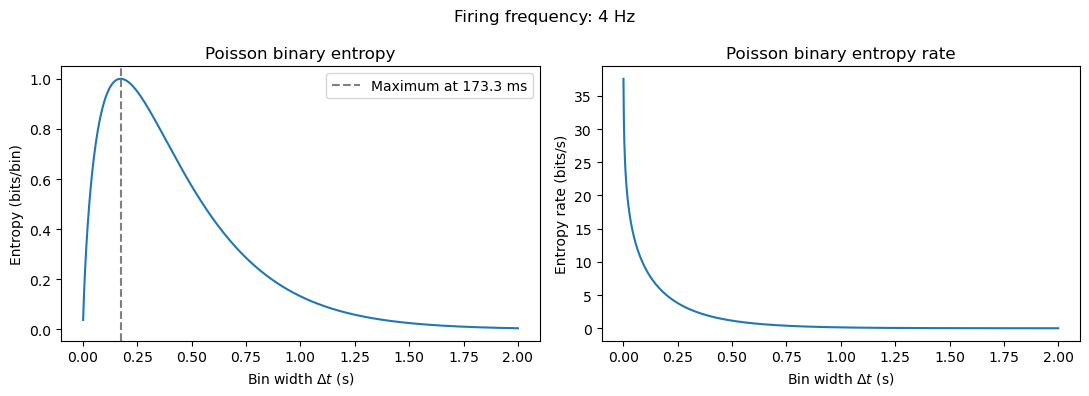

Entropy at 10 ms: 0.2387 bits/bin
Entropy rate at 10 ms: 23.87 bits/s


In [17]:
def poisson_binary_entropy(f, dt):
    """Entropy in bits of binarised Poisson activity in one time bin."""
    p1 = -np.expm1(-f * dt)
    p0 = 1.0 - p1

    # Mask zero probabilities to implement the convention 0 * log(0) = 0.
    term0 = p0 * np.log2(p0, out=np.zeros_like(p0), where=p0 > 0)
    term1 = p1 * np.log2(p1, out=np.zeros_like(p1), where=p1 > 0)
    return -(term0 + term1)

f = 4.0  # Hz
dt = np.linspace(0.001, 2.0, 2000)  # seconds; exclude zero
entropy = poisson_binary_entropy(f, dt)
entropy_rate = entropy / dt
dt_max = np.log(2) / f

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(dt, entropy)
axes[0].axvline(
    dt_max, color="gray", linestyle="--",
    label=f"Maximum at {dt_max * 1000:.1f} ms",
)
axes[0].set(
    xlabel=r"Bin width $\Delta t$ (s)",
    ylabel="Entropy (bits/bin)",
    title="Poisson binary entropy",
)
axes[0].legend()

axes[1].plot(dt, entropy_rate)
axes[1].set(
    xlabel=r"Bin width $\Delta t$ (s)",
    ylabel="Entropy rate (bits/s)",
    title="Poisson binary entropy rate",
)


fig.suptitle(f"Firing frequency: {f:g} Hz")
plt.tight_layout()
plt.show()

dt_tutorial = 0.010
s = float(poisson_binary_entropy(f, dt_tutorial))
print(f"Entropy at 10 ms: {s:.4f} bits/bin")
print(f"Entropy rate at 10 ms: {s / dt_tutorial:.2f} bits/s")

## Question 2: Information Conveyed by the Spike Train

### 2a. Mutual Information

Let $B$ denote the starting bin of a word within the movie, chosen uniformly among all valid starting positions, and let $W$ denote the observed spike word.

The probability of a word, averaged over movie positions, is:

$$
p(W)=\sum_b p(b)\,p(W\mid b).
$$

The total entropy measures the variability of words across the recording:

$$
S_{\mathrm{total}}=H(W)
=-\sum_W p(W)\log_2 p(W).
$$

At a fixed movie position $b$, the entropy across repetitions is:

$$
S(b)=H(W\mid B=b)
=-\sum_W p(W\mid b)\log_2 p(W\mid b).
$$

Averaging over movie positions gives the noise entropy:

$$
S_{\mathrm{noise}}
=\sum_b p(b)S(b)
=H(W\mid B).
$$

Therefore,

$$
\boxed{
I=S_{\mathrm{total}}-S_{\mathrm{noise}}
=H(W)-H(W\mid B)=I(W;B).
}
$$

Equivalently,

$$
I(W;B)
=
\sum_{W,b}p(W,b)
\log_2\frac{p(W,b)}{p(W)p(b)}
=
D_{\mathrm{KL}}\!\left(p(W,B)\,\Vert\,p(W)p(B)\right)
\geq 0.
$$

Thus, $I$ is the mutual information between the spike word and the movie position, which serves as the stimulus label in this repeated-movie experiment.

### 2b. Estimation from Data

We use bins of width $\Delta t=10$ ms and words of $\ell=10$ bins. Each word lasts:

$$
\tau_W=\ell\Delta t=0.1\ \mathrm{s},
$$

and there are $2^{10}=1024$ possible binary words.

For each neuron:

1. Convert the spike times into a binary matrix with repetitions as rows and movie bins as columns.
2. Extract overlapping words, keeping each word within its repetition.
3. Pool words across repetitions and starting positions to estimate $p(W)$.
4. At each starting position, use repetitions to estimate $p(W\mid b)$.
5. Calculate total entropy, average noise entropy, and their difference.

To express these quantities as rates, divide the entropy per word by the **word duration**:

$$
R_{\mathrm{total}}=\frac{S_{\mathrm{total}}}{\ell\Delta t},
\qquad
R_{\mathrm{noise}}=\frac{S_{\mathrm{noise}}}{\ell\Delta t},
\qquad
R_I=\frac{I}{\ell\Delta t}.
$$

The fraction of response variability associated with the stimulus is:

$$
\boxed{\frac{I}{S_{\mathrm{total}}}.}
$$

For a homogeneous Poisson model with frequency $f_i$, bins are independent, so:

$$
S_{\mathrm{Poisson,word}}=\ell S_p(f_i,\Delta t),
\qquad
R_{\mathrm{Poisson}}=\frac{S_p(f_i,\Delta t)}{\Delta t}.
$$

This provides a reference for comparison. Strictly, the independent-bin upper bound at a fixed observed occupancy $q_i$ is $\ell h_2(q_i)$; the Poisson reference uses the model occupancy $1-e^{-f_i\Delta t}$.

These are empirical estimates from finite data. In particular, limited repetitions tend to underestimate noise entropy and can overestimate mutual information, which we investigate in Question 3.

In [23]:
from numpy.lib.stride_tricks import sliding_window_view

T = 26.5
n_repetitions = 120
dt = 0.010
word_length = 10
n_bins = int(round(T / dt))
word_duration = word_length * dt


def entropy_from_counts(counts, axis=-1):
    counts = np.asarray(counts, dtype=float)
    totals = counts.sum(axis=axis, keepdims=True)
    p = np.divide(
        counts, totals, out=np.zeros_like(counts), where=totals > 0
    )
    log_p = np.log2(p, out=np.zeros_like(p), where=p > 0)
    return -(p * log_p).sum(axis=axis)


def bin_spikes(times):
    times = np.asarray(times, dtype=float)
    # Use the half-open recording interval [0, n_repetitions * T).
    times = times[(times >= 0) & (times < n_repetitions * T)]
    repetitions = np.floor(times / T).astype(int)
    movie_times = times - repetitions * T
    bins = np.floor(movie_times / dt).astype(int)
    bins = np.clip(bins, 0, n_bins - 1)

    binary = np.zeros((n_repetitions, n_bins), dtype=np.uint8)
    binary[repetitions, bins] = 1
    firing_rate = len(times) / (n_repetitions * T)
    return binary, firing_rate


def analyse_neuron(times):
    binary, firing_rate = bin_spikes(times)

    # Shape: repetitions x starting positions x bins per word.
    windows = sliding_window_view(binary, word_length, axis=1)
    weights = 1 << np.arange(word_length, dtype=np.int64)
    words = windows @ weights

    n_words = 2 ** word_length
    total_counts = np.bincount(words.ravel(), minlength=n_words)
    s_total = float(entropy_from_counts(total_counts))

    # Estimate a separate word distribution at each movie position.
    position_entropies = np.array([
        entropy_from_counts(
            np.bincount(words[:, b], minlength=n_words)
        )
        for b in range(words.shape[1])
    ])
    s_noise = float(position_entropies.mean())
    information = s_total - s_noise

    return {
        "frequency_hz": firing_rate,
        "total_bits": s_total,
        "noise_bits": s_noise,
        "information_bits": information,
        "total_rate": s_total / word_duration,
        "noise_rate": s_noise / word_duration,
        "information_rate": information / word_duration,
        "information_fraction": (
            information / s_total if s_total > 0 else np.nan
        ),
    }

# One array of spike times per neuron.
# Skip the 4000 marker and the neuron label.
spike_times = [
    data[tc[i] + 2 : tc[i + 1]]
    for i in range(Ncells)
]

results = pd.DataFrame(
    [analyse_neuron(times) for times in spike_times],
    index=pd.Index(range(1, len(spike_times) + 1), name="neuron"),
)

display(results.round(4))
display(
    results[
        ["total_rate", "noise_rate",
         "information_rate", "information_fraction"]
    ].describe().round(3)
)

fraction = results["information_fraction"].mean()
print(f"Mean information fraction across neurons: {fraction:.1%}")

,frequency_hz,total_bits,noise_bits,information_bits,total_rate,noise_rate,information_rate,information_fraction
neuron,,,,,,,,
1,4.0327,2.3188,1.4358,0.8830,23.1876,14.3577,8.8299,0.3808
2,0.4874,0.4404,0.2500,0.1904,4.4035,2.4999,1.9037,0.4323
3,0.6220,0.5450,0.3578,0.1872,5.4496,3.5775,1.8721,0.3435
4,0.4443,0.3980,0.2336,0.1644,3.9795,2.3359,1.6436,0.4130
5,2.7214,1.5345,0.7825,0.7520,15.3446,7.8248,7.5198,0.4901
6,2.7692,1.5607,0.7729,0.7877,15.6069,7.7294,7.8775,0.5047
7,0.4997,0.4289,0.2550,0.1738,4.2885,2.5505,1.7381,0.4053
8,1.2113,0.9082,0.5492,0.3590,9.0817,5.4920,3.5896,0.3953
9,1.1689,0.8158,0.4056,0.4102,8.1584,4.0561,4.1023,0.5028


,total_rate,noise_rate,information_rate,information_fraction
count,40.000,40.000,40.000,40.000
mean,8.413,4.573,3.840,0.462
std,5.871,3.264,2.748,0.072
min,2.550,1.234,1.295,0.231
25%,4.249,2.352,1.896,0.420
50%,6.244,3.452,2.799,0.480
75%,10.522,5.784,4.737,0.507
max,24.444,14.358,12.108,0.595


Mean information fraction across neurons: 46.2%


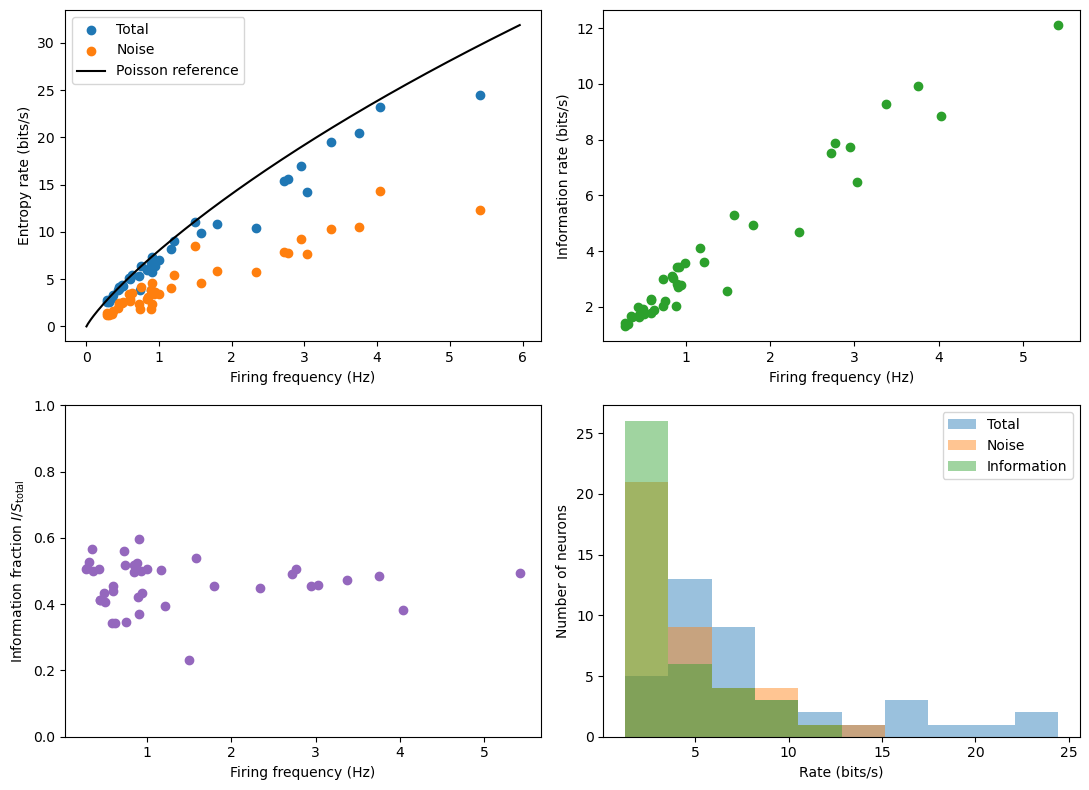

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
f = results["frequency_hz"]
f_grid = np.linspace(0, max(float(f.max()) * 1.1, 0.1), 300)

axes[0, 0].scatter(f, results["total_rate"], label="Total")
axes[0, 0].scatter(f, results["noise_rate"], label="Noise")
axes[0, 0].plot(
    f_grid,
    poisson_binary_entropy(f_grid, dt) / dt,
    color="black",
    label="Poisson reference",
)
axes[0, 0].set_ylabel("Entropy rate (bits/s)")
axes[0, 0].legend()

axes[0, 1].scatter(f, results["information_rate"], color="tab:green")
axes[0, 1].set_ylabel("Information rate (bits/s)")

axes[1, 0].scatter(
    f, results["information_fraction"], color="tab:purple"
)
axes[1, 0].set_ylabel(r"Information fraction $I/S_{\mathrm{total}}$")
axes[1, 0].set_ylim(0, 1)

for ax in axes.flat[:3]:
    ax.set_xlabel("Firing frequency (Hz)")

rate_columns = ["total_rate", "noise_rate", "information_rate"]
all_rates = results[rate_columns].to_numpy().ravel()
edges = np.histogram_bin_edges(all_rates, bins=10)

for column, label in zip(rate_columns, ["Total", "Noise", "Information"]):
    axes[1, 1].hist(
        results[column], bins=edges, alpha=0.45, label=label
    )

axes[1, 1].set_xlabel("Rate (bits/s)")
axes[1, 1].set_ylabel("Number of neurons")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Interpretation

- **Entropy increases with firing rate:** more active neurons produce more variable spike words. Total entropy lies mostly below the Poisson reference, consistent with temporal structure in their responses.
- **Information increases with firing rate:** more active neurons generally convey more information about the movie, with estimated rates of approximately 1-12 bits/s.
- **Around half the variability is informative:** most values of $I/S_{\mathrm{total}}$ are near 0.5, with no clear dependence on firing rate. This is a fraction of entropy, not a fraction of spikes.
- **Most neurons have low rates:** the distributions have long right tails, with a few neurons showing much higher entropy and information rates.

Limited data can inflate information estimates; Question 3 examines their stability.

## Question 3: Effects of Sample Size and Word Length

We investigate whether the estimated information rate is stable when changing:

- The number of movie repetitions used.
- The word length $\ell$.

For each configuration, we calculate:

$$
R_I=\frac{S_{\mathrm{total}}-S_{\mathrm{noise}}}{\ell\Delta t}.
$$

### Number of Repetitions

With few repetitions, many possible words are never observed at a given movie position. This tends to underestimate noise entropy and inflate the estimated information.

In particular, with only one repetition, each position has one observed word, so the estimated noise entropy is zero. This is a sampling artefact, not evidence of a deterministic response.

A stable information rate as the number of repetitions increases suggests that sampling is becoming sufficient for the chosen word length.

### Word Length

Longer words capture more temporal structure, but the number of possible words grows exponentially:

$$
N_W=2^\ell.
$$

Consequently, longer words require more data. We examine whether information **per second**, rather than information per word, approaches a plateau.

A plateau supports stability over the tested range, but does not prove convergence: finite-sample bias can still affect the estimates.

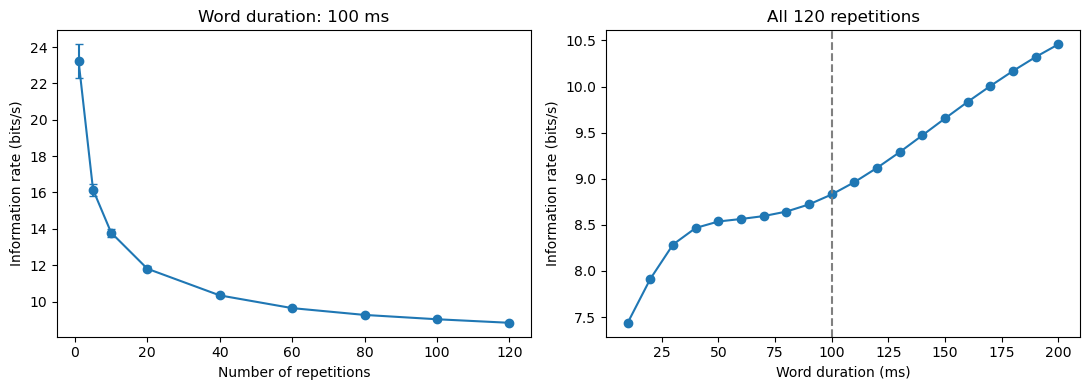

,repetitions,mean_information_rate,subset_std
0,1,23.237,0.919
1,5,16.154,0.334
2,10,13.790,0.217
3,20,11.804,0.135
4,40,10.338,0.069
5,60,9.638,0.028
6,80,9.263,0.038
7,100,9.025,0.016
8,120,8.830,0.000


,word_length,duration_ms,information_rate
0,1,10.0,7.438
1,2,20.0,7.915
2,3,30.0,8.287
3,4,40.0,8.466
4,5,50.0,8.537
5,6,60.0,8.564
6,7,70.0,8.595
7,8,80.0,8.644
8,9,90.0,8.722
9,10,100.0,8.830


In [29]:
from numpy.lib.stride_tricks import sliding_window_view

binary, _ = bin_spikes(spike_times[0])
rng = np.random.default_rng(42)


def encode_words(binary, length):
    windows = sliding_window_view(binary, length, axis=1)
    weights = 1 << np.arange(length, dtype=np.int64)
    return windows @ weights


def estimate_word_information(words):
    _, total_counts = np.unique(words, return_counts=True)
    s_total = float(entropy_from_counts(total_counts))

    # Count observed words separately at each movie position.
    # Sorting avoids constructing a potentially huge 2**length table.
    sorted_words = np.sort(words, axis=0)
    starts = np.vstack([
        np.ones((1, words.shape[1]), dtype=bool),
        sorted_words[1:] != sorted_words[:-1],
    ])
    rows, positions = np.nonzero(starts)
    order = np.lexsort((rows, positions))
    rows, positions = rows[order], positions[order]

    next_rows = np.r_[rows[1:], words.shape[0]]
    same_position = np.r_[positions[1:] == positions[:-1], False]
    counts = np.where(
        same_position, next_rows - rows, words.shape[0] - rows
    )
    probabilities = counts / words.shape[0]
    s_by_position = np.bincount(
        positions,
        weights=-probabilities * np.log2(probabilities),
        minlength=words.shape[1],
    )
    s_noise = float(s_by_position.mean())
    return s_total, s_noise, s_total - s_noise


# 1. Change repetition count, keeping words at 10 bins.
words_10 = encode_words(binary, 10)
repetition_counts = np.array([1, 5, 10, 20, 40, 60, 80, 100, 120])
n_subsets = 10
sample_rates = []

for n in repetition_counts:
    rates = []
    for _ in range(n_subsets if n < len(binary) else 1):
        subset = rng.choice(len(binary), size=n, replace=False)
        _, _, information = estimate_word_information(words_10[subset])
        rates.append(information / (10 * dt))
    sample_rates.append(rates)

means = np.array([np.mean(rates) for rates in sample_rates])
stds = np.array([
    np.std(rates, ddof=1) if len(rates) > 1 else 0
    for rates in sample_rates
])

# 2. Change word length using all repetitions.
lengths = np.arange(1, 21)
length_rates = []

for length in lengths:
    words = encode_words(binary, length)
    _, _, information = estimate_word_information(words)
    length_rates.append(information / (length * dt))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].errorbar(
    repetition_counts, means, yerr=stds,
    marker="o", capsize=3,
)
axes[0].set(
    xlabel="Number of repetitions",
    ylabel="Information rate (bits/s)",
    title="Word duration: 100 ms",
)

axes[1].plot(lengths * dt * 1000, length_rates, marker="o")
axes[1].axvline(100, color="gray", linestyle="--")
axes[1].set(
    xlabel="Word duration (ms)",
    ylabel="Information rate (bits/s)",
    title="All 120 repetitions",
)

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "repetitions": repetition_counts,
    "mean_information_rate": means,
    "subset_std": stds,
}).round(3))

display(pd.DataFrame({
    "word_length": lengths,
    "duration_ms": lengths * dt * 1000,
    "information_rate": length_rates,
}).round(3))

### Interpretation

- **Increasing repetitions reduces the estimated information rate**, consistent with reduced sampling bias. The curve flattens near 120 repetitions but still decreases slightly, so full convergence is not established.
- **Increasing word duration does not produce a clear plateau.** Beyond 100 ms, the estimated rate rises, potentially reflecting additional temporal information or stronger finite-sample bias as the number of possible words grows.

Thus, 120 repetitions and 10-bin words give an estimate near **8.8 bits/s** for this neuron, but these plots do not establish that either parameter is sufficient for convergence.

### Plot the entropy as a function of the time (bin number) and compare with the frequency.  